# 02 — Pre-injury trajectories and matched controls

**Objective.** Compare changes from each pitcher’s prior baseline as documented injuries approach, including non-arm negative comparisons.

**Cohort and interpretation.** Eligible events require at least three quality outings in the preceding 60 days and one within 14 days. Controls match year/month, index-outing role, five-year age band and prior-appearance experience band. Each control pitcher is used once, with no observed nearby IL episode and horizon follow-up. Pair selection uses outcome information solely to define the comparison, never predictors. All CIs are exploratory pitcher-cluster bootstrap intervals; no row-independent significance tests.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config/injury_analysis.yaml").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.injury_analysis.common import CFG, CACHE, OUT, read_table, table, conclusion, style
from src.injury_analysis.cohort import load
from src.injury_analysis import plots
style()
pd.set_option('display.max_columns', 14)


In [2]:
from src.injury_analysis.trajectories import build_trajectories
a, events, spec = load()
aligned, matches, effects = build_trajectories(a, events)
display(matches.groupby(['analysis_group','is_starter']).agg(pairs=('event_id','size'),case_pitchers=('pitcher_id','nunique')).reset_index())
display(read_table('trajectory_exclusions').reason.value_counts().rename('events'))
print(f"{len(matches):,} matched event/control pairs; {matches.control_pitcher_id.nunique():,} unique control pitchers.")

,analysis_group,is_starter,pairs,case_pitchers
0,Elbow / UCL,False,146,138
1,Elbow / UCL,True,79,74
2,Forearm,False,53,51
3,Forearm,True,31,30
4,Hand / wrist,False,35,32
5,Hand / wrist,True,33,32
6,Lower body,False,172,152
7,Lower body,True,108,91
8,Other arm,False,57,56
9,Other arm,True,28,28


reason
no unused matched control pitcher                            1376
fewer than 3 prior outings in 60d or no outing within 14d     927
no MLB pitcher appearance history                              24
Name: events, dtype: int64

1,225 matched event/control pairs; 1,225 unique control pitchers.


## Calendar time and appearance-relative time
Calendar bins summarize 31–60, 15–30, 8–14 and 1–7 days before the index date. Each event contributes one mean per bin; frequent relievers do not gain extra weight within a bin. Appearance-relative plots show the last five outings within the 60-day window. Solid lines are cases, dashed lines their controls. Bands resample case pitchers. The number of observed events varies across bins/features; the full count columns are saved.

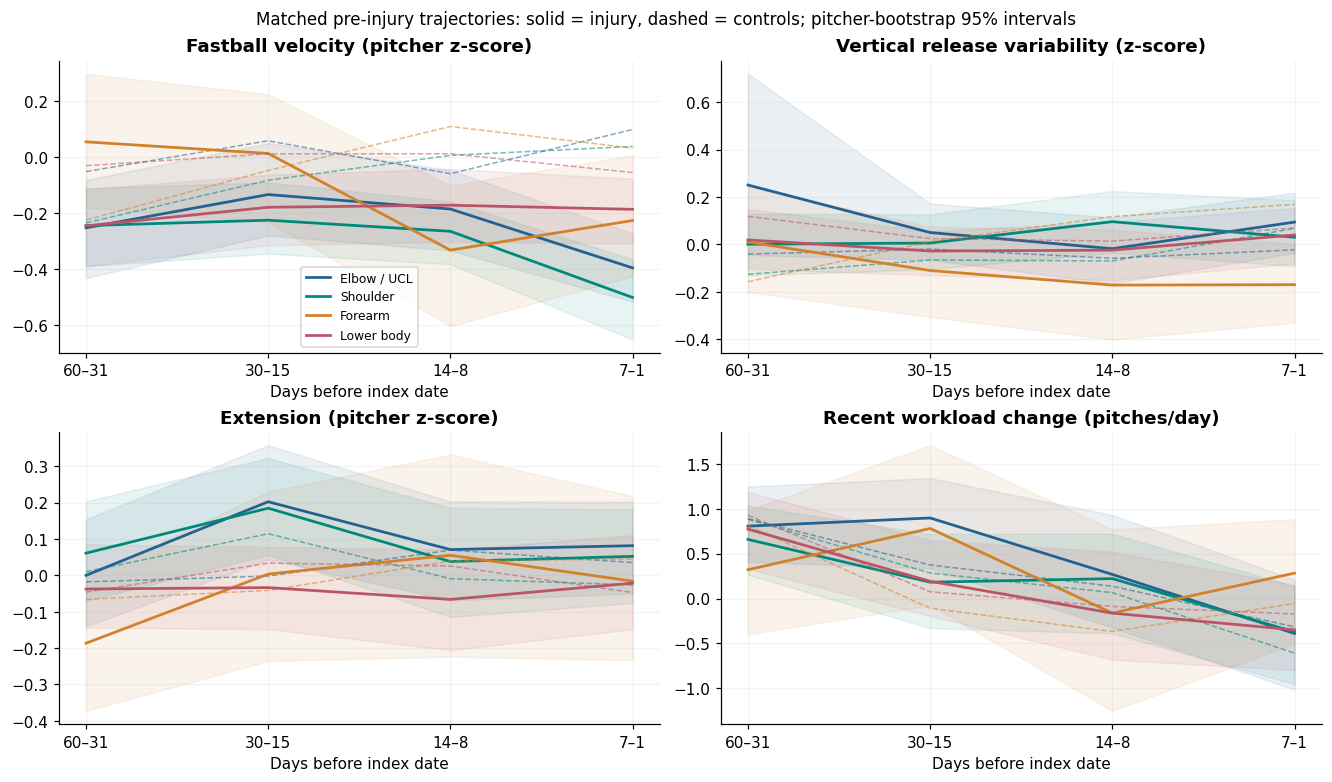

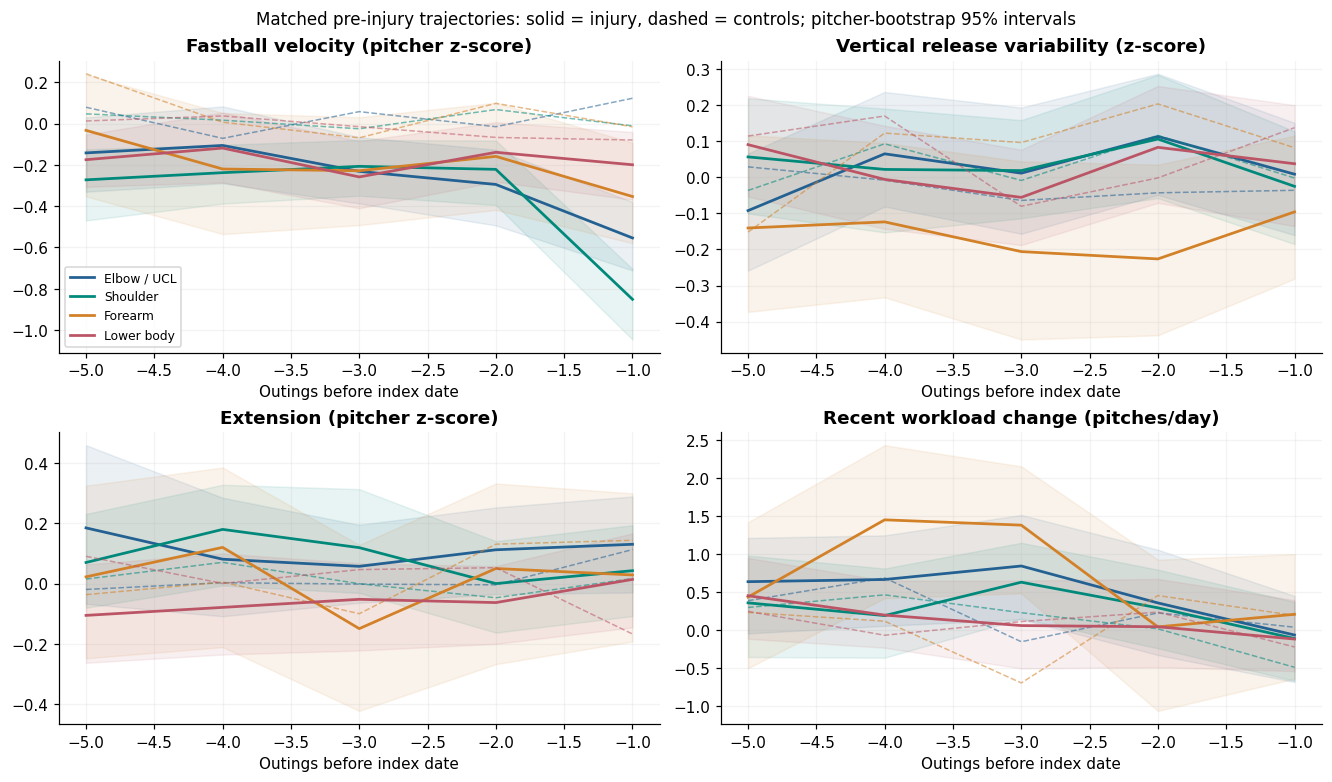

,analysis_group,kind,window,mean,n,pitchers
0,Elbow / UCL,Control,15–30 days,0.058939,194,182
9,Elbow / UCL,Control,1–7 days,0.099309,223,209
18,Elbow / UCL,Control,31–60 days,-0.051364,156,150
27,Elbow / UCL,Control,8–14 days,-0.058774,200,189
36,Elbow / UCL,Injury,15–30 days,-0.133712,192,182
45,Elbow / UCL,Injury,1–7 days,-0.396485,223,209
54,Elbow / UCL,Injury,31–60 days,-0.252939,152,144
63,Elbow / UCL,Injury,8–14 days,-0.185514,196,186
72,Forearm,Control,15–30 days,-0.047490,68,65
81,Forearm,Control,1–7 days,0.032788,83,80


In [3]:
plots.trajectory_figure('calendar'); plt.show()
plots.trajectory_figure('appearance'); plt.show()
display(read_table('calendar_trajectory_summary').query("feature == 'velo_z'")[['analysis_group','kind','window','mean','n','pitchers']])

## Matched effect sizes and anatomical specificity
The next figure uses one 1–14-day feature mean per matched event and plots injury minus control. Trunk/lower-body injuries test whether similar warning patterns also occur outside the arm. Arm-region labels alone do not establish throwing-side involvement; the second table requires explicit laterality for that comparison. There is no multiplicity-adjusted hypothesis test or causal interpretation.

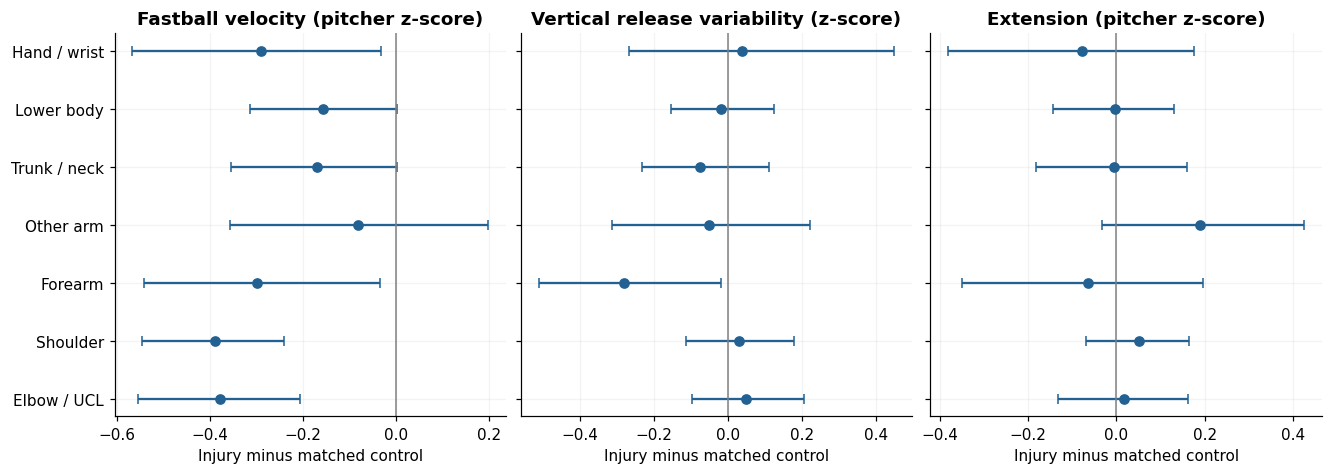

,analysis_group,feature,mean,low,high,n,pitchers
0,Elbow / UCL,velo_z,-0.377916,-0.553631,-0.206769,225,211
9,Forearm,velo_z,-0.298698,-0.542208,-0.032927,84,81
18,Hand / wrist,velo_z,-0.288796,-0.566156,-0.031679,68,63
27,Lower body,velo_z,-0.157474,-0.314385,0.002093,280,235
36,Other arm,velo_z,-0.081816,-0.356707,0.199160,85,83
45,Shoulder,velo_z,-0.389256,-0.546234,-0.240988,276,240
54,Trunk / neck,velo_z,-0.169246,-0.354488,0.002838,206,182


,group,feature,mean,low,high,n,pitchers
0,Explicit throwing-side arm,velo_z,-0.340126,-0.443567,-0.240882,654,529
3,Explicit throwing-side arm,release_z_sd_z,-0.013176,-0.100470,0.071241,655,530
4,Explicit throwing-side arm,extension_z,0.037523,-0.056721,0.116359,655,530
9,Non-arm (trunk/lower body),velo_z,-0.162464,-0.276206,-0.051472,486,390
12,Non-arm (trunk/lower body),release_z_sd_z,-0.043013,-0.143905,0.066449,486,390
13,Non-arm (trunk/lower body),extension_z,-0.004066,-0.107626,0.087588,486,390
18,Other or uncertain side,velo_z,-0.258412,-0.574954,0.019252,84,77
21,Other or uncertain side,release_z_sd_z,0.028878,-0.272934,0.358066,84,77
22,Other or uncertain side,extension_z,-0.017320,-0.276351,0.233455,84,77


**Computed conclusion.** Matched shoulder outings differ from controls by -0.39 velocity z-units (95% interval -0.55 to -0.24); elbow/UCL differs by -0.38. Lower-body difference is -0.16. These are group-level pre-IL associations, not proof of a specific injury mechanism or reliable individual warning.

In [4]:
plots.effects_figure(); plt.show()
display(effects.query("feature == 'velo_z'"))
body = read_table('body_group_preinjury_effects')
display(body[body.feature.isin(['velo_z','release_z_sd_z','extension_z'])])
v=effects.query("feature == 'velo_z'").set_index('analysis_group')
conclusion(f"Matched shoulder outings differ from controls by {v.loc['Shoulder','mean']:.2f} velocity z-units (95% interval {v.loc['Shoulder','low']:.2f} to {v.loc['Shoulder','high']:.2f}); elbow/UCL differs by {v.loc['Elbow / UCL','mean']:.2f}. Lower-body difference is {v.loc['Lower body','mean']:.2f}. These are group-level pre-IL associations, not proof of a specific injury mechanism or reliable individual warning.")